# Studio Proyek 3 — Fine-Tuning Transformer Pretrained untuk Klasifikasi Sentimen (SmSA)
**Pembelajaran Mendalam (IF25-40401) · ITERA**

Alur notebook: Konfigurasi → **Rancangan (Soal 1)** → Data → Utilitas freezing → Training → Jalankan matriks → Agregasi → Grafik → Bahan analisis.

**Cara pakai**
1. Runtime GPU (T4). Kaggle: nyalakan *Internet* (buat download dataset & model).
2. Jalankan dengan `MODE = "smoke"` dulu (cuma beberapa menit) buat mastiin pipeline jalan.
3. Edit sel **Rancangan** pakai kata-kata kalian sendiri, ganti `MODE = "full"`, lalu Run All.
4. Kalau Colab putus, jalankan ulang: run yang sudah selesai otomatis di-skip (hasil disimpan per run ke CSV).

In [1]:
import os, gc, time, json, hashlib, warnings
import numpy as np, pandas as pd
import torch
from torch.utils.data import DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup, set_seed)
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = device == "cuda"
print("device:", device, "|", torch.cuda.get_device_name(0) if USE_AMP else "TANPA GPU (akan sangat lambat)")

device: cuda | Tesla T4


## 0. Konfigurasi (variabel yang dikunci)
Semua run memakai nilai yang sama persis. Hanya **seed**, **backbone**, dan **strategi** yang berubah.

In [2]:
MODE = "full"          # "smoke" = uji cepat | "full" = eksperimen sebenarnya (wajib isi sel Rancangan)
DATASET = "smsa"

# --- Backbone (hanya model multibahasa / Indonesia; model English-only DILARANG di SmSA) ---
BACKBONES = {
    "BERT-mBERT":   "bert-base-multilingual-cased",         # wajib (baseline)
    "DistilBERT-m": "distilbert-base-multilingual-cased",   # wajib
    "IndoBERT":     "indobenchmark/indobert-base-p1",       # wajib untuk SmSA
}
INCLUDE_XLMR = False    # opsional (nilai plus): True -> tambah xlm-roberta-base (+9 run)
if INCLUDE_XLMR:
    BACKBONES["XLM-R"] = "xlm-roberta-base"

# --- Strategi. "head replacement" otomatis di semua run (num_labels=3). Minimal full + (probing ATAU partial) ---
STRATEGIES = ["full", "partial", "probing"]   # buang salah satu dari partial/probing kalau waktu mepet (18 run)
LR = {"full": 3e-5, "partial": 3e-5, "probing": 2e-3}   # sesuai ketentuan: 2e-5..5e-5 / 1e-3..5e-3

if MODE == "full":
    CFG = dict(max_len=128, batch=32, epochs=3, train_subset=5000, warmup=0.1, wd=0.01, data_seed=42)
    SEEDS = [42, 123, 2026]       # minimal 3 seed, SAMA untuk semua run
else:
    CFG = dict(max_len=64,  batch=32, epochs=1, train_subset=256,  warmup=0.1, wd=0.01, data_seed=42)
    SEEDS = [42]

# Opsional: bagi kerja antar-anggota. Contoh: ONLY_BACKBONES = ["IndoBERT"]
ONLY_BACKBONES = None
# Opsional: gabungkan file hasil_*.csv dari anggota lain (upload dulu), isi nama filenya di sini
EXTRA_RESULT_FILES = []

_hash_cfg = dict(mode=MODE, cfg=CFG, lr=LR, backbones=BACKBONES)
KODE = hashlib.md5(json.dumps(_hash_cfg, sort_keys=True).encode()).hexdigest()[:6]
RES_FILE = f"hasil_{DATASET}_{KODE}.csv"
AGG_FILE = f"rekap_agregat_{DATASET}_{KODE}.csv"
print("MODE:", MODE, "| kode konfigurasi:", KODE)
print("CFG:", CFG, "| SEEDS:", SEEDS)
print("File hasil:", RES_FILE, "|", AGG_FILE)

MODE: full | kode konfigurasi: ef01c6
CFG: {'max_len': 128, 'batch': 32, 'epochs': 3, 'train_subset': 5000, 'warmup': 0.1, 'wd': 0.01, 'data_seed': 42} | SEEDS: [42, 123, 2026]
File hasil: hasil_smsa_ef01c6.csv | rekap_agregat_smsa_ef01c6.csv


## 1. Rancangan Eksperimen (Soal 1)
> **Wajib diedit.** Isi di bawah ini draft awal — ubah pakai alasan & hipotesis kalian sendiri **sebelum** menjalankan eksperimen. Pada `MODE = "full"`, notebook menolak jalan kalau bagian ini kosong atau masih berisi `TODO`.

In [3]:
RANCANGAN = {
 "H1": "H1 (backbone): Dengan full fine-tuning, IndoBERT akan menghasilkan F1 makro tertinggi, diikuti mBERT lalu DistilBERT-m, "
       "karena IndoBERT dipralatih khusus pada teks Bahasa Indonesia sedangkan model multibahasa membagi kapasitasnya ke banyak bahasa.",
 "H2": "H2 (strategi): Urutan kualitas full > partial freezing > linear probing. Linear probing turun paling jauh (representasi beku "
       "tidak disesuaikan ke domain sentimen), tetapi waktu latih dan memori puncaknya paling kecil.",
 "H3": "H3 (efisiensi): DistilBERT-m (6 lapis vs 12) inferensinya jauh lebih cepat dari mBERT dengan penurunan F1 makro yang kecil, "
       "sehingga jadi pilihan terbaik kalau anggaran komputasi atau latensi dibatasi.",
 "alasan_dataset_dan_subset": "SmSA (IndoNLU) dipilih karena berbahasa Indonesia, 3 kelas (negatif/netral/positif), punya pembagian resmi train/valid/test. "
       "Train di-subsample stratified sebesar train_subset supaya 27 run muat di GPU T4 gratis; valid & test dipakai utuh.",
 "alasan_desain": "Matriks 3 backbone x 3 strategi x 3 seed = 27 run. Backbone dibatasi ke model multibahasa/Indonesia agar perbandingan tidak "
       "tercampur faktor bahasa. Learning rate disesuaikan per strategi (probing jauh lebih besar). Hasil dilaporkan rata-rata ± std antar-seed.",
}
RANCANGAN["variabel_terkendali"] = (
    f"max_length={CFG['max_len']}, batch_size={CFG['batch']}, epoch={CFG['epochs']}, train_subset={CFG['train_subset']}, "
    f"warmup={CFG['warmup']}, weight_decay={CFG['wd']}, optimizer=AdamW, lr={LR}, seed={SEEDS}, data_seed={CFG['data_seed']}, "
    f"fp16={USE_AMP}, pembagian data=resmi SmSA (dibersihkan)."
)

def cek_rancangan():
    kosong = [k for k, v in RANCANGAN.items() if len(str(v).strip()) < 30 or "TODO" in str(v)]
    if kosong and MODE == "full":
        raise RuntimeError(f"Sel Rancangan belum lengkap: {kosong}. Isi dulu sebelum mode full.")
    return kosong

print("Bagian rancangan bermasalah:", cek_rancangan() or "tidak ada")

# Tabel matriks backbone x strategi (rencana sel yang akan diisi)
matriks = pd.DataFrame({s: [f"{len(SEEDS)} seed" for _ in BACKBONES] for s in STRATEGIES}, index=list(BACKBONES))
matriks.index.name = "backbone \\ strategi"
display(matriks)
print("Total run:", len(BACKBONES) * len(STRATEGIES) * len(SEEDS))
for k, v in RANCANGAN.items(): print(f"\n[{k}] {v}")

Bagian rancangan bermasalah: tidak ada


,full,partial,probing
backbone \ strategi,,,
BERT-mBERT,3 seed,3 seed,3 seed
DistilBERT-m,3 seed,3 seed,3 seed
IndoBERT,3 seed,3 seed,3 seed


Total run: 27

[H1] H1 (backbone): Dengan full fine-tuning, IndoBERT akan menghasilkan F1 makro tertinggi, diikuti mBERT lalu DistilBERT-m, karena IndoBERT dipralatih khusus pada teks Bahasa Indonesia sedangkan model multibahasa membagi kapasitasnya ke banyak bahasa.

[H2] H2 (strategi): Urutan kualitas full > partial freezing > linear probing. Linear probing turun paling jauh (representasi beku tidak disesuaikan ke domain sentimen), tetapi waktu latih dan memori puncaknya paling kecil.

[H3] H3 (efisiensi): DistilBERT-m (6 lapis vs 12) inferensinya jauh lebih cepat dari mBERT dengan penurunan F1 makro yang kecil, sehingga jadi pilihan terbaik kalau anggaran komputasi atau latensi dibatasi.

[alasan_dataset_dan_subset] SmSA (IndoNLU) dipilih karena berbahasa Indonesia, 3 kelas (negatif/netral/positif), punya pembagian resmi train/valid/test. Train di-subsample stratified sebesar train_subset supaya 27 run muat di GPU T4 gratis; valid & test dipakai utuh.

[alasan_desain] Matriks 3 back

## 2. Data SmSA + pembersihan
Pembagian resmi. Dibuang: duplikat, teks berlabel bertentangan, dan teks validasi yang muncul di data latih.

In [4]:
LABELS = ["negative", "neutral", "positive"]
L2I = {l: i for i, l in enumerate(LABELS)}
I2L = {i: l for l, i in L2I.items()}
BASE_URL = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/"

def read_split(name):
    for p in [f"{name}_preprocess.tsv", f"/kaggle/input/smsa/{name}_preprocess.tsv", f"/content/{name}_preprocess.tsv"]:
        if os.path.exists(p):
            return pd.read_csv(p, sep="\t", header=None, names=["text", "label"])
    try:
        return pd.read_csv(BASE_URL + f"{name}_preprocess.tsv", sep="\t", header=None, names=["text", "label"])
    except Exception as e:
        raise RuntimeError(f"Gagal download {name}. Nyalakan Internet (Kaggle) atau upload {name}_preprocess.tsv "
                           f"dari repo IndoNLP/indonlu ke folder kerja. Detail: {e}")

raw = {s: read_split(s).dropna() for s in ["train", "valid", "test"]}
print({k: len(v) for k, v in raw.items()}, "(mentah)")

def drop_dup_conflict(df):
    n = df.groupby("text")["label"].nunique()
    bad = set(n[n > 1].index)
    out = df[~df["text"].isin(bad)].drop_duplicates("text").reset_index(drop=True)
    return out, len(bad)

train, n_bad_tr = drop_dup_conflict(raw["train"])
valid, n_bad_va = drop_dup_conflict(raw["valid"])
n_leak = valid["text"].isin(set(train["text"])).sum()
valid = valid[~valid["text"].isin(set(train["text"]))].reset_index(drop=True)
test = raw["test"].reset_index(drop=True)
n_test_overlap = test["text"].isin(set(train["text"])).sum()   # hanya info, tidak dibuang (test resmi)

for d in (train, valid, test):
    d["y"] = d["label"].map(L2I)
    assert d["y"].notna().all(), "ada label di luar negative/neutral/positive"
    d["y"] = d["y"].astype(int)

print(f"Dibuang -> teks label bertentangan: train {n_bad_tr}, valid {n_bad_va} | valid yang bocor di train: {n_leak}")
print(f"Info: kalimat test yang ada juga di train: {n_test_overlap}")
print({"train": len(train), "valid": len(valid), "test": len(test)}, "(bersih)")

if CFG["train_subset"] and CFG["train_subset"] < len(train):
    train_s, _ = train_test_split(train, train_size=CFG["train_subset"], stratify=train["y"], random_state=CFG["data_seed"])
    train_s = train_s.reset_index(drop=True)
else:
    train_s = train
print("Train dipakai:", len(train_s))
print("Distribusi kelas (train_s):", train_s["label"].value_counts().to_dict())
print("Distribusi kelas (test):   ", test["label"].value_counts().to_dict())

{'train': 11000, 'valid': 1260, 'test': 500} (mentah)
Dibuang -> teks label bertentangan: train 0, valid 0 | valid yang bocor di train: 14
Info: kalimat test yang ada juga di train: 0
{'train': 10933, 'valid': 1246, 'test': 500} (bersih)
Train dipakai: 5000
Distribusi kelas (train_s): {'positive': 2919, 'negative': 1560, 'neutral': 521}
Distribusi kelas (test):    {'positive': 208, 'negative': 204, 'neutral': 88}


## 3. Strategi fine-tuning: head replacement, freezing, linear probing
- **Head replacement**: `AutoModelForSequenceClassification(..., num_labels=3)` membuang head pretrained & membuat head baru 3 kelas (warning "newly initialized" itu memang yang diharapkan).
- **Full**: semua parameter dilatih. **Partial**: embedding + separuh lapis awal dibekukan (12→6, DistilBERT 6→3). **Probing**: seluruh backbone dibekukan, hanya head dilatih.

In [5]:
def get_parts(model):
    base = model.base_model
    emb = base.embeddings
    layers = base.encoder.layer if hasattr(base, "encoder") else base.transformer.layer  # BERT/XLM-R vs DistilBERT
    return base, emb, layers

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def apply_strategy(model, strategy):
    base, emb, layers = get_parts(model)
    for p in model.parameters():          # reset: semua trainable dulu (head baru selalu trainable)
        p.requires_grad = True
    if strategy == "full":
        pass
    elif strategy == "probing":
        for p in base.parameters():       # bekukan SELURUH backbone; head klasifikasi tetap dilatih
            p.requires_grad = False
    elif strategy == "partial":
        for p in emb.parameters():        # bekukan embedding
            p.requires_grad = False
        n_freeze = len(layers) // 2       # 12 -> 6, 6 -> 3
        for layer in layers[:n_freeze]:   # bekukan separuh lapis awal
            for p in layer.parameters():
                p.requires_grad = False
    else:
        raise ValueError(strategy)
    return model

def load_model(name):
    return AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=len(LABELS), id2label=I2L, label2id=L2I)   # <- HEAD REPLACEMENT

# Cek urutan parameter dilatih: probing < partial < full (jalan di CPU, sekali per backbone)
rows = []
for bb, name in BACKBONES.items():
    m = load_model(name)
    cnt = {}
    for s in ["probing", "partial", "full"]:
        apply_strategy(m, s)
        tot, tr = count_params(m)
        cnt[s] = tr
    assert cnt["probing"] < cnt["partial"] < cnt["full"], f"urutan parameter salah di {bb}: {cnt}"
    rows.append({"backbone": bb, "lapis": len(get_parts(m)[2]), "total": tot, **{f"dilatih_{k}": v for k, v in cnt.items()}})
    del m; gc.collect()
display(pd.DataFrame(rows))
print("OK: probing < partial < full untuk semua backbone")

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

... (10 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

,backbone,lapis,total,dilatih_probing,dilatih_partial,dilatih_full
0,BERT-mBERT,12,177855747,2307,43120131,177855747
1,DistilBERT-m,6,135326979,592899,21856515,135326979
2,IndoBERT,12,124443651,2307,43120131,124443651


OK: probing < partial < full untuk semua backbone


## 4. Fungsi training & evaluasi
Optimizer AdamW + linear warmup/decay, fp16 autocast. Waktu inferensi diukur forward-pass saja (batch 64, setelah warmup, ms/kalimat) pada test set — **bandingkan hanya dalam satu sesi yang sama**.

In [6]:
_cache = {}
def get_data(bb):
    if bb in _cache: return _cache[bb]
    tok = AutoTokenizer.from_pretrained(BACKBONES[bb])
    def enc(df):
        e = tok(df["text"].tolist(), truncation=True, max_length=CFG["max_len"])
        keys = list(e.keys())
        out = []
        for i in range(len(df)):
            item = {k: e[k][i] for k in keys}
            item["labels"] = int(df["y"].iloc[i])
            out.append(item)
        return out
    _cache[bb] = (tok, enc(train_s), enc(valid), enc(test))
    return _cache[bb]

def make_collate(tok):
    def collate(items):
        labels = torch.tensor([it["labels"] for it in items])
        feats = [{k: v for k, v in it.items() if k != "labels"} for it in items]
        b = dict(tok.pad(feats, return_tensors="pt"))
        b["labels"] = labels
        return b
    return collate

def sync():
    if USE_AMP: torch.cuda.synchronize()

@torch.no_grad()
def predict(model, feats, collate, bs=64, time_it=False):
    model.eval()
    batches = []
    for i in range(0, len(feats), bs):
        b = collate(feats[i:i + bs])
        batches.append({k: v.to(device) for k, v in b.items()})
    labels = torch.cat([b["labels"] for b in batches]).cpu().numpy()
    inputs = [{k: v for k, v in b.items() if k != "labels"} for b in batches]
    if time_it:                                   # warmup
        for x in inputs[:2]:
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                model(**x)
    sync(); t0 = time.perf_counter()
    preds = []
    for x in inputs:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**x).logits
        preds.append(logits.argmax(-1).cpu())
    sync(); dt = time.perf_counter() - t0
    preds = torch.cat(preds).numpy()
    return preds, labels, dt / len(feats) * 1000.0   # ms / kalimat

def metrics(y, p):
    f1_cls = f1_score(y, p, average=None, labels=[0, 1, 2], zero_division=0)
    return dict(acc=accuracy_score(y, p), f1=f1_score(y, p, average="macro", zero_division=0),
                f1_neg=f1_cls[0], f1_neu=f1_cls[1], f1_pos=f1_cls[2])

def run_one(bb, strategy, seed):
    set_seed(seed)
    tok, tr_f, va_f, te_f = get_data(bb)
    collate = make_collate(tok)
    model = apply_strategy(load_model(BACKBONES[bb]), strategy).to(device)
    total, trainable = count_params(model)
    params = [p for p in model.parameters() if p.requires_grad]

    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(tr_f, batch_size=CFG["batch"], shuffle=True, collate_fn=collate, generator=g)
    steps = len(dl) * CFG["epochs"]
    opt = torch.optim.AdamW(params, lr=LR[strategy], weight_decay=CFG["wd"])
    sch = get_linear_schedule_with_warmup(opt, int(CFG["warmup"] * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    if USE_AMP: torch.cuda.reset_peak_memory_stats()
    sync(); t0 = time.perf_counter()
    last_losses = []
    for ep in range(CFG["epochs"]):
        model.train()
        for b in dl:
            b = {k: v.to(device) for k, v in b.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**b).loss
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sch.step(); opt.zero_grad(set_to_none=True)
            if ep == CFG["epochs"] - 1: last_losses.append(loss.item())
    sync(); train_time = time.perf_counter() - t0
    peak_mem = torch.cuda.max_memory_allocated() / 2**20 if USE_AMP else float("nan")

    pv, yv, _ = predict(model, va_f, collate)
    pt, yt, ms = predict(model, te_f, collate, time_it=True)
    mt, mv = metrics(yt, pt), metrics(yv, pv)
    row = dict(dataset=DATASET, backbone=bb, model_name=BACKBONES[bb], strategy=strategy, seed=seed, lr=LR[strategy],
               test_acc=mt["acc"], test_f1_macro=mt["f1"], f1_neg=mt["f1_neg"], f1_neu=mt["f1_neu"], f1_pos=mt["f1_pos"],
               val_acc=mv["acc"], val_f1_macro=mv["f1"], final_train_loss=float(np.mean(last_losses)),
               train_time_s=train_time, infer_ms_per_sentence=ms,
               params_total=total, params_trainable=trainable, peak_mem_mb=peak_mem)
    del model, opt, sch, scaler; gc.collect()
    if USE_AMP: torch.cuda.empty_cache()
    return row

## 5. Jalankan matriks eksperimen
Hasil disimpan **per run** ke `hasil_<dataset>_<kode>.csv`; run yang sudah ada di-skip (aman kalau runtime putus).

In [7]:
cek_rancangan()   # menolak jalan di mode full kalau Rancangan kosong

done = pd.read_csv(RES_FILE) if os.path.exists(RES_FILE) else pd.DataFrame()
done_keys = set(zip(done["backbone"], done["strategy"], done["seed"])) if len(done) else set()

todo = [(bb, s, sd) for bb in BACKBONES if (ONLY_BACKBONES is None or bb in ONLY_BACKBONES)
        for s in STRATEGIES for sd in SEEDS if (bb, s, sd) not in done_keys]
print(f"Run tersisa: {len(todo)} (sudah selesai: {len(done_keys)})")

t_all = time.time()
for i, (bb, s, sd) in enumerate(todo, 1):
    t0 = time.time()
    row = run_one(bb, s, sd)
    pd.concat([done, pd.DataFrame([row])], ignore_index=True).to_csv(RES_FILE, index=False)
    done = pd.read_csv(RES_FILE)
    print(f"[{i}/{len(todo)}] {bb:13s} {s:8s} seed={sd:<5d} F1={row['test_f1_macro']:.4f} acc={row['test_acc']:.4f} "
          f"latih={row['train_time_s']:.0f}s infer={row['infer_ms_per_sentence']:.2f}ms  ({time.time()-t0:.0f}s)")
print(f"Selesai dalam {(time.time()-t_all)/60:.1f} menit -> {RES_FILE}")

Run tersisa: 27 (sudah selesai: 0)


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (82 outputs left out)

[26/27] IndoBERT      probing  seed=123   F1=0.7177 acc=0.7700 latih=21s infer=0.93ms  (24s)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[27/27] IndoBERT      probing  seed=2026  F1=0.7261 acc=0.7840 latih=20s infer=0.93ms  (24s)
Selesai dalam 22.8 menit -> hasil_smsa_ef01c6.csv


## 6. Agregasi: rata-rata ± simpangan baku antar-seed

In [8]:
parts = [pd.read_csv(RES_FILE)] + [pd.read_csv(f) for f in EXTRA_RESULT_FILES]
df = pd.concat(parts, ignore_index=True).drop_duplicates(["backbone", "strategy", "seed"])
B_ORDER, S_ORDER = list(BACKBONES), ["full", "partial", "probing"]

cols = ["test_acc", "test_f1_macro", "f1_neg", "f1_neu", "f1_pos", "train_time_s",
        "infer_ms_per_sentence", "peak_mem_mb", "params_total", "params_trainable"]
g = df.groupby(["backbone", "strategy"])
agg = g[cols].mean().add_suffix("_mean").join(g[cols].std(ddof=1).add_suffix("_std")).join(g.size().rename("n_seed")).reset_index()
agg["backbone"] = pd.Categorical(agg["backbone"], B_ORDER, ordered=True)
agg["strategy"] = pd.Categorical(agg["strategy"], S_ORDER, ordered=True)
agg = agg.sort_values(["backbone", "strategy"]).reset_index(drop=True)
agg.to_csv(AGG_FILE, index=False)

def pm(r, c, d=4): return f"{r[c+'_mean']:.{d}f} ± {r[c+'_std']:.{d}f}" if r["n_seed"] > 1 else f"{r[c+'_mean']:.{d}f}"
tabel = pd.DataFrame({
    "backbone": agg["backbone"], "strategi": agg["strategy"], "n_seed": agg["n_seed"],
    "Akurasi": agg.apply(lambda r: pm(r, "test_acc"), axis=1),
    "F1 makro": agg.apply(lambda r: pm(r, "test_f1_macro"), axis=1),
    "Waktu latih (s)": agg.apply(lambda r: pm(r, "train_time_s", 1), axis=1),
    "Inferensi (ms/kal)": agg.apply(lambda r: pm(r, "infer_ms_per_sentence", 3), axis=1),
    "Param total (M)": (agg["params_total_mean"] / 1e6).round(1),
    "Param dilatih (M)": (agg["params_trainable_mean"] / 1e6).round(1),
    "Mem puncak (MB)": agg["peak_mem_mb_mean"].round(0),
})
display(tabel)
print("Tersimpan:", AGG_FILE)
if len(df) and df["seed"].nunique() < 3: print("PERINGATAN: kurang dari 3 seed — belum memenuhi ketentuan.")

,backbone,strategi,n_seed,Akurasi,F1 makro,Waktu latih (s),Inferensi (ms/kal),Param total (M),Param dilatih (M),Mem puncak (MB)
0,BERT-mBERT,full,3,0.8233 ± 0.0076,0.7836 ± 0.0092,101.1 ± 2.0,1.132 ± 0.062,177.9,177.9,3883.0
1,BERT-mBERT,partial,3,0.7207 ± 0.0110,0.6819 ± 0.0132,54.3 ± 0.1,1.186 ± 0.005,177.9,43.1,1957.0
2,BERT-mBERT,probing,3,0.5053 ± 0.0070,0.4019 ± 0.0147,26.4 ± 0.0,1.183 ± 0.005,177.9,0.0,786.0
3,DistilBERT-m,full,3,0.7773 ± 0.0103,0.7401 ± 0.0101,59.3 ± 0.2,0.600 ± 0.006,135.3,135.3,2623.0
4,DistilBERT-m,partial,3,0.6567 ± 0.0145,0.6126 ± 0.0129,26.8 ± 0.1,0.608 ± 0.003,135.3,21.9,1185.0
5,DistilBERT-m,probing,3,0.5753 ± 0.0090,0.5165 ± 0.0166,13.6 ± 0.0,0.603 ± 0.004,135.3,0.6,622.0
6,IndoBERT,full,3,0.9113 ± 0.0081,0.8827 ± 0.0134,78.0 ± 0.1,0.926 ± 0.005,124.4,124.4,3000.0
7,IndoBERT,partial,3,0.9093 ± 0.0058,0.8791 ± 0.0074,44.4 ± 0.0,0.934 ± 0.007,124.4,43.1,1618.0
8,IndoBERT,probing,3,0.7787 ± 0.0076,0.7241 ± 0.0057,20.6 ± 0.1,0.934 ± 0.006,124.4,0.0,569.0


Tersimpan: rekap_agregat_smsa_ef01c6.csv


## 7. Grafik

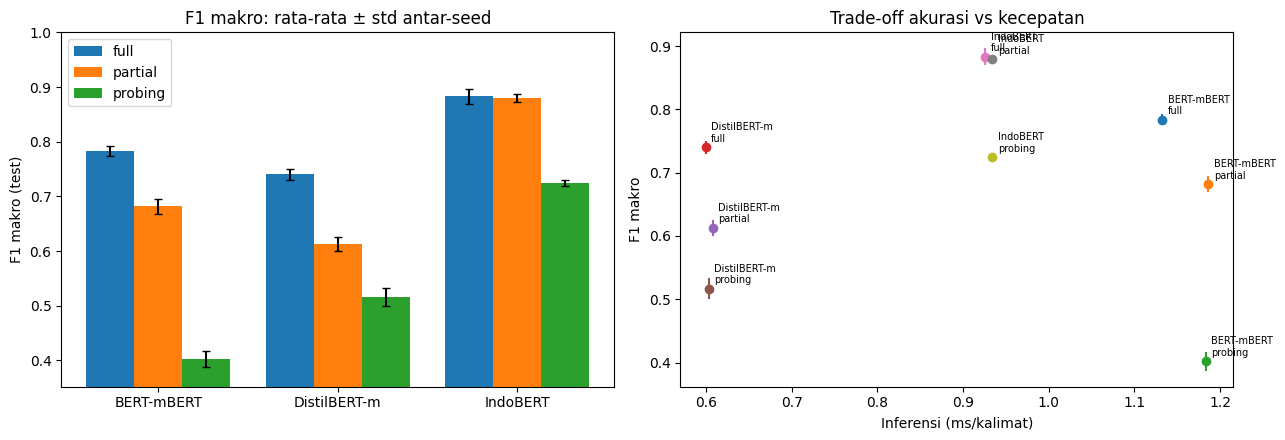

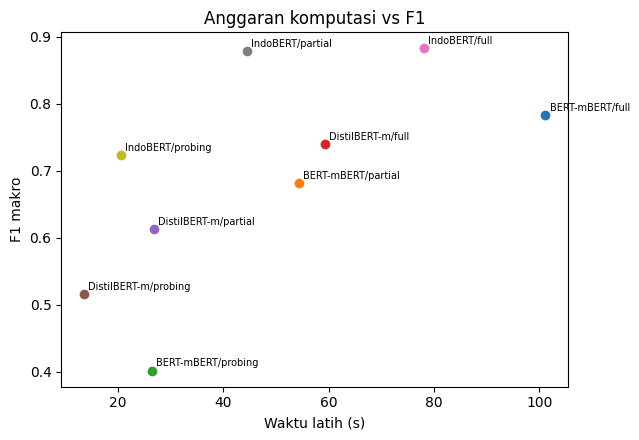

In [9]:
bbs = [b for b in B_ORDER if b in set(agg["backbone"])]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
w = 0.8 / len(S_ORDER)
for j, s in enumerate(S_ORDER):
    sub = agg[agg["strategy"] == s].set_index("backbone").reindex(bbs)
    ax[0].bar(np.arange(len(bbs)) + j * w, sub["test_f1_macro_mean"], w,
              yerr=sub["test_f1_macro_std"].fillna(0), capsize=3, label=s)
ax[0].set_xticks(np.arange(len(bbs)) + w * (len(S_ORDER) - 1) / 2); ax[0].set_xticklabels(bbs)
ax[0].set_ylabel("F1 makro (test)"); ax[0].set_title("F1 makro: rata-rata ± std antar-seed"); ax[0].legend()
lo = max(0, agg["test_f1_macro_mean"].min() - 0.05); ax[0].set_ylim(lo, 1.0)

for _, r in agg.iterrows():
    ax[1].errorbar(r["infer_ms_per_sentence_mean"], r["test_f1_macro_mean"], yerr=0 if pd.isna(r["test_f1_macro_std"]) else r["test_f1_macro_std"], fmt="o")
    ax[1].annotate(f"{r['backbone']}\n{r['strategy']}", (r["infer_ms_per_sentence_mean"], r["test_f1_macro_mean"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax[1].set_xlabel("Inferensi (ms/kalimat)"); ax[1].set_ylabel("F1 makro"); ax[1].set_title("Trade-off akurasi vs kecepatan")
plt.tight_layout(); plt.savefig(f"grafik_{DATASET}_{KODE}.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for _, r in agg.iterrows():
    ax.scatter(r["train_time_s_mean"], r["test_f1_macro_mean"])
    ax.annotate(f"{r['backbone']}/{r['strategy']}", (r["train_time_s_mean"], r["test_f1_macro_mean"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Waktu latih (s)"); ax.set_ylabel("F1 makro"); ax.set_title("Anggaran komputasi vs F1")
plt.tight_layout(); plt.savefig(f"grafik_biaya_{DATASET}_{KODE}.png", dpi=150); plt.show()

## 8. Bahan analisis (angka siap kutip ke laporan)

In [10]:
best = agg.sort_values("test_f1_macro_mean", ascending=False).iloc[0]
print(f"Konfigurasi F1 tertinggi: {best['backbone']} / {best['strategy']}  F1={best['test_f1_macro_mean']:.4f} ± {best['test_f1_macro_std']:.4f}")
fast = agg.sort_values("infer_ms_per_sentence_mean").iloc[0]
print(f"Inferensi tercepat: {fast['backbone']} / {fast['strategy']}  {fast['infer_ms_per_sentence_mean']:.3f} ms/kalimat (F1={fast['test_f1_macro_mean']:.4f})")

print("\n== Selisih vs full fine-tuning, per backbone (dipasangkan per seed) ==")
piv = df.pivot_table(index=["backbone", "seed"], columns="strategy", values="test_f1_macro")
tpiv = df.pivot_table(index=["backbone", "seed"], columns="strategy", values="train_time_s")
for bb in bbs:
    if bb not in piv.index.get_level_values(0): continue
    for s in ["partial", "probing"]:
        if s in piv.columns and "full" in piv.columns:
            d = (piv.loc[bb][s] - piv.loc[bb]["full"]).dropna()
            tt = (tpiv.loc[bb][s] / tpiv.loc[bb]["full"]).dropna()
            if len(d): print(f"{bb:13s} {s:8s} ΔF1 = {d.mean():+.4f} ± {d.std(ddof=1) if len(d)>1 else 0:.4f} | waktu latih {tt.mean()*100:.0f}% dari full")

print("\n== Perbandingan backbone pada full fine-tuning ==")
f = agg[agg["strategy"] == "full"].set_index("backbone")
for bb in f.index:
    print(f"{bb:13s} F1={f.loc[bb,'test_f1_macro_mean']:.4f}  infer={f.loc[bb,'infer_ms_per_sentence_mean']:.3f}ms  "
          f"param={f.loc[bb,'params_total_mean']/1e6:.1f}M  latih={f.loc[bb,'train_time_s_mean']:.0f}s")

print("\n== F1 per kelas (kelas netral biasanya paling sulit) ==")
display(agg[["backbone", "strategy", "f1_neg_mean", "f1_neu_mean", "f1_pos_mean"]].round(4))

Konfigurasi F1 tertinggi: IndoBERT / full  F1=0.8827 ± 0.0134
Inferensi tercepat: DistilBERT-m / full  0.600 ms/kalimat (F1=0.7401)

== Selisih vs full fine-tuning, per backbone (dipasangkan per seed) ==
BERT-mBERT    partial  ΔF1 = -0.1017 ± 0.0209 | waktu latih 54% dari full
BERT-mBERT    probing  ΔF1 = -0.3817 ± 0.0189 | waktu latih 26% dari full
DistilBERT-m  partial  ΔF1 = -0.1275 ± 0.0227 | waktu latih 45% dari full
DistilBERT-m  probing  ΔF1 = -0.2235 ± 0.0155 | waktu latih 23% dari full
IndoBERT      partial  ΔF1 = -0.0037 ± 0.0203 | waktu latih 57% dari full
IndoBERT      probing  ΔF1 = -0.1587 ± 0.0114 | waktu latih 26% dari full

== Perbandingan backbone pada full fine-tuning ==
BERT-mBERT    F1=0.7836  infer=1.132ms  param=177.9M  latih=101s
DistilBERT-m  F1=0.7401  infer=0.600ms  param=135.3M  latih=59s
IndoBERT      F1=0.8827  infer=0.926ms  param=124.4M  latih=78s

== F1 per kelas (kelas netral biasanya paling sulit) ==


,backbone,strategy,f1_neg_mean,f1_neu_mean,f1_pos_mean
0,BERT-mBERT,full,0.8458,0.6447,0.8603
1,BERT-mBERT,partial,0.7743,0.5603,0.7109
2,BERT-mBERT,probing,0.5048,0.1250,0.5760
3,DistilBERT-m,full,0.8124,0.6091,0.7987
4,DistilBERT-m,partial,0.7162,0.4817,0.6398
5,DistilBERT-m,probing,0.6654,0.3662,0.5181
6,IndoBERT,full,0.9447,0.7775,0.9260
7,IndoBERT,partial,0.9504,0.7676,0.9192
8,IndoBERT,probing,0.8342,0.5399,0.7982


## 9. Kesimpulan & jawaban Pertanyaan Riset Wajib
*(Isi sendiri berdasarkan angka di Bagian 6–8. Tulis dengan bukti: sebut rata-rata ± std, bandingkan dengan H1–H3, dan jujur kalau hipotesis tidak terbukti.)*

**Pertanyaan Riset 1:** _(salin dari spesifikasi/dosen)_

**Pertanyaan Riset 2:** _(salin dari spesifikasi/dosen)_

**Pertanyaan Riset 3:** _(salin dari spesifikasi/dosen)_

**Rekomendasi akhir (strategi + backbone):** _alasannya harus menyebut akurasi, anggaran komputasi, kecepatan inferensi, dan keterjelasan._

**Catatan keterbatasan:** subset train, jumlah seed (3), satu dataset, waktu inferensi hanya valid dalam satu sesi/GPU.

---
**Checklist pengumpulan** — (1) link notebook, (2) PDF `STUDIO3_Kelompok[X]_[Nama1]_[Nama2].pdf` dari notebook yang sudah dijalankan penuh, (3) `hasil_*.csv` + `rekap_agregat_*.csv`, (4) slide ≤15 + laporan 3–4 halaman. Deadline notebook & berkas: **20 November 2026**.